# Discovering Communities in a Real-World Network Using Louvain and Girvan-Newman

**Dataset:** `socfb-Caltech36`, a Facebook friendship network from NetworkRepository.

**Goal:** Prepare the graph, analyze its structural properties, apply Louvain and Girvan-Newman community detection, then compare the detected communities by modularity, size, runtime, and visual separation.


## 1. Setup

The notebook installs missing packages only when they are not already available. This keeps the project reproducible while avoiding unnecessary installs on a prepared environment.


In [1]:
import importlib.util
import subprocess
import sys

required_packages = {
    "networkx": "networkx",
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "community": "python-louvain",
    "requests": "requests",
}

missing = [
    pip_name
    for module_name, pip_name in required_packages.items()
    if importlib.util.find_spec(module_name) is None
]

if missing:
    print("Installing missing packages:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are available.")


All required packages are available.


In [2]:
import io
import statistics
import time
import zipfile
from pathlib import Path

import community as community_louvain
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from networkx.algorithms.community import modularity
from networkx.algorithms.community.centrality import girvan_newman

RANDOM_SEED = 42
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
FIGURE_DIR = PROJECT_DIR / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

DATASET_NAME = "socfb-Caltech36"
DATASET_PAGE = "https://networkrepository.com/socfb_Caltech36.php"
DATASET_ZIP_URL = "https://nrvis.com/download/data/socfb/socfb-Caltech36.zip"
DATASET_ZIP_PATH = DATA_DIR / "socfb-Caltech36.zip"
MATRIX_MEMBER = "socfb-Caltech36.mtx"

plt.style.use("seaborn-v0_8-whitegrid")


## 2. Data Collection and Graph Preparation

NetworkRepository provides this graph in MatrixMarket format. The file is marked as symmetric, so each listed coordinate is interpreted as one undirected friendship edge.


In [3]:
def download_dataset(url: str, output_path: Path) -> None:
    if output_path.exists():
        print(f"Using cached dataset: {output_path}")
        return

    response = requests.get(url, timeout=60)
    response.raise_for_status()
    output_path.write_bytes(response.content)
    print(f"Downloaded dataset to: {output_path}")


def load_symmetric_matrix_market_graph(zip_path: Path, member_name: str) -> nx.Graph:
    graph = nx.Graph()

    with zipfile.ZipFile(zip_path) as archive:
        raw_text = archive.read(member_name).decode("utf-8")

    dimensions_read = False
    for raw_line in raw_text.splitlines():
        line = raw_line.strip()
        if not line or line.startswith("%"):
            continue

        parts = line.split()
        if not dimensions_read:
            node_count = int(parts[0])
            graph.add_nodes_from(range(1, node_count + 1))
            dimensions_read = True
            continue

        if len(parts) >= 2:
            source, target = int(parts[0]), int(parts[1])
            if source != target:
                graph.add_edge(source, target)

    return graph


download_dataset(DATASET_ZIP_URL, DATASET_ZIP_PATH)
G = load_symmetric_matrix_market_graph(DATASET_ZIP_PATH, MATRIX_MEMBER)
components = sorted(nx.connected_components(G), key=len, reverse=True)
G_lcc = G.subgraph(components[0]).copy()

print(f"Dataset: {DATASET_NAME}")
print(f"Source page: {DATASET_PAGE}")
print(f"Nodes: {G.number_of_nodes():,}")
print(f"Unique undirected edges: {G.number_of_edges():,}")
print(f"Connected components: {len(components):,}")
print(f"Largest connected component: {G_lcc.number_of_nodes():,} nodes, {G_lcc.number_of_edges():,} edges")


Using cached dataset: /Users/kris/Desktop/3283/project2/data/socfb-Caltech36.zip
Dataset: socfb-Caltech36
Source page: https://networkrepository.com/socfb_Caltech36.php
Nodes: 769
Unique undirected edges: 16,656
Connected components: 4
Largest connected component: 762 nodes, 16,651 edges


In [4]:
degrees = dict(G.degree())
lcc_degrees = dict(G_lcc.degree())

basic_properties = pd.DataFrame(
    [
        ["Nodes", G.number_of_nodes()],
        ["Unique undirected edges", G.number_of_edges()],
        ["Average degree", np.mean(list(degrees.values()))],
        ["Minimum degree", min(degrees.values())],
        ["Maximum degree", max(degrees.values())],
        ["Density", nx.density(G)],
        ["Connected components", nx.number_connected_components(G)],
        ["Largest component nodes", G_lcc.number_of_nodes()],
        ["Largest component edges", G_lcc.number_of_edges()],
        ["Largest component average shortest path length", nx.average_shortest_path_length(G_lcc)],
        ["Largest component diameter", nx.diameter(G_lcc)],
        ["Largest component radius", nx.radius(G_lcc)],
    ],
    columns=["Property", "Value"],
)

display(basic_properties)


,Property,Value
0,Nodes,769.000000
1,Unique undirected edges,16656.000000
2,Average degree,43.318596
3,Minimum degree,1.000000
4,Maximum degree,248.000000
5,Density,0.056404
6,Connected components,4.000000
7,Largest component nodes,762.000000
8,Largest component edges,16651.000000
9,Largest component average shortest path length,2.337848


**Interpretation.** The graph is dense for a social network of this size, with many friendship ties among a relatively small university population. The largest connected component contains almost all nodes, so shortest-path and community visualizations are based on that component when a connected graph is required.


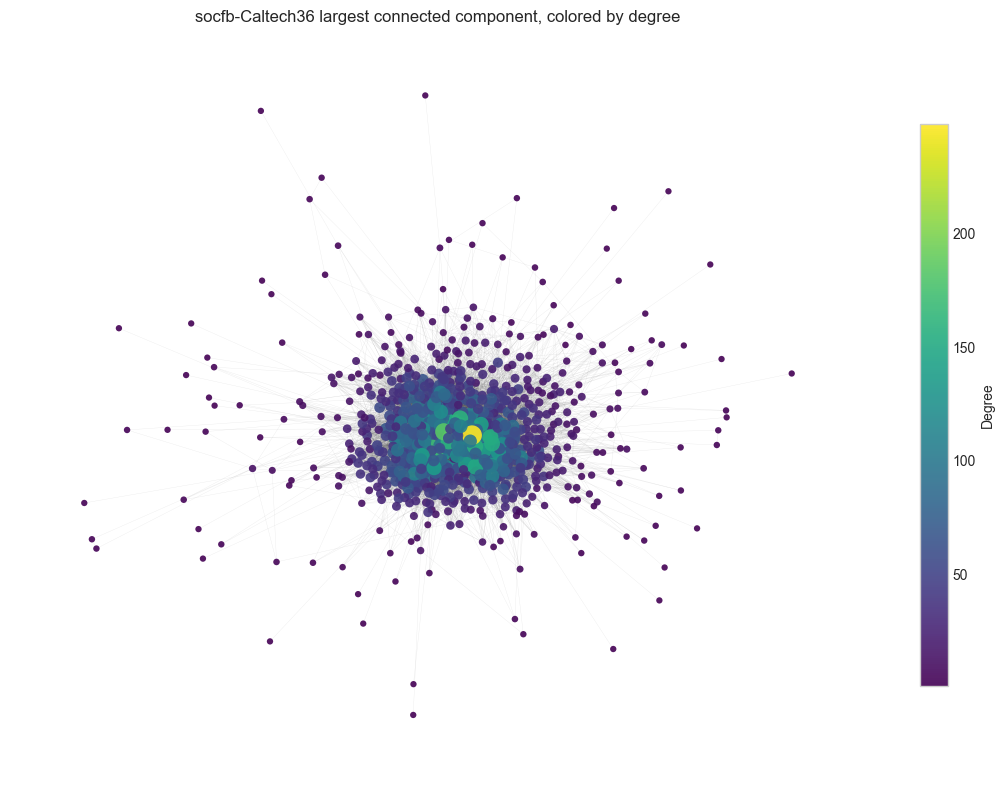

Spring layout runtime: 1.30 seconds


In [5]:
layout_start = time.perf_counter()
pos_lcc = nx.spring_layout(G_lcc, seed=RANDOM_SEED, iterations=60, k=0.12)
layout_time = time.perf_counter() - layout_start

node_sizes = [20 + 180 * (lcc_degrees[node] / max(lcc_degrees.values())) for node in G_lcc.nodes()]

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G_lcc, pos_lcc, ax=ax, width=0.25, alpha=0.12, edge_color="#555555")
nodes = nx.draw_networkx_nodes(
    G_lcc,
    pos_lcc,
    ax=ax,
    node_color=[lcc_degrees[node] for node in G_lcc.nodes()],
    node_size=node_sizes,
    cmap="viridis",
    linewidths=0,
    alpha=0.9,
)
ax.set_title("socfb-Caltech36 largest connected component, colored by degree")
ax.axis("off")
cbar = fig.colorbar(nodes, ax=ax, shrink=0.75)
cbar.set_label("Degree")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_graph_degree_visualization.png", dpi=180)
plt.show()

print(f"Spring layout runtime: {layout_time:.2f} seconds")


## 3. Centrality Analysis

Degree centrality identifies highly connected students. Betweenness centrality identifies nodes that lie on many shortest paths and may bridge groups. Closeness centrality identifies nodes that are structurally near many others. Eigenvector centrality highlights nodes connected to other influential nodes.


In [6]:
centrality_start = time.perf_counter()
degree_centrality = nx.degree_centrality(G_lcc)
betweenness_centrality = nx.betweenness_centrality(G_lcc)
closeness_centrality = nx.closeness_centrality(G_lcc)
eigenvector_centrality = nx.eigenvector_centrality(G_lcc, max_iter=1000)
centrality_runtime = time.perf_counter() - centrality_start

centrality_df = pd.DataFrame(
    {
        "node": list(G_lcc.nodes()),
        "degree": [degree_centrality[n] for n in G_lcc.nodes()],
        "betweenness": [betweenness_centrality[n] for n in G_lcc.nodes()],
        "closeness": [closeness_centrality[n] for n in G_lcc.nodes()],
        "eigenvector": [eigenvector_centrality[n] for n in G_lcc.nodes()],
        "raw_degree": [G_lcc.degree(n) for n in G_lcc.nodes()],
    }
)

print(f"Centrality runtime: {centrality_runtime:.2f} seconds")
print("Top nodes by each centrality measure:")
for metric in ["degree", "betweenness", "closeness", "eigenvector"]:
    print(f"\nTop 8 by {metric}:")
    display(centrality_df.sort_values(metric, ascending=False).head(8)[["node", "raw_degree", metric]])

top_degree_nodes = centrality_df.sort_values("degree", ascending=False).head(8)["node"].tolist()
top_degree_betweenness = centrality_df[centrality_df["node"].isin(top_degree_nodes)][
    ["node", "raw_degree", "degree", "betweenness"]
].sort_values("degree", ascending=False)

print("\nBetweenness values for the 8 highest-degree nodes:")
display(top_degree_betweenness)


Centrality runtime: 2.23 seconds
Top nodes by each centrality measure:

Top 8 by degree:


,node,raw_degree,degree
701,709,248,0.325887
86,90,203,0.266754
216,223,194,0.254928
656,664,184,0.241787
250,257,172,0.226018
271,278,171,0.224704
679,687,160,0.210250
615,623,160,0.210250



Top 8 by betweenness:


,node,raw_degree,betweenness
701,709,248,0.047949
216,223,194,0.043367
271,278,171,0.030954
86,90,203,0.029342
348,355,144,0.022289
727,735,152,0.021845
630,638,157,0.018686
656,664,184,0.018633



Top 8 by closeness:


,node,raw_degree,closeness
701,709,248,0.574773
86,90,203,0.553052
216,223,194,0.543960
271,278,171,0.538570
679,687,160,0.537050
656,664,184,0.535162
250,257,172,0.532540
727,735,152,0.531054



Top 8 by eigenvector:


,node,raw_degree,eigenvector
701,709,248,0.131991
86,90,203,0.116052
615,623,160,0.114047
250,257,172,0.111609
656,664,184,0.107220
216,223,194,0.100884
679,687,160,0.097354
370,377,144,0.095733



Betweenness values for the 8 highest-degree nodes:


,node,raw_degree,degree,betweenness
701,709,248,0.325887,0.047949
86,90,203,0.266754,0.029342
216,223,194,0.254928,0.043367
656,664,184,0.241787,0.018633
250,257,172,0.226018,0.012856
271,278,171,0.224704,0.030954
615,623,160,0.210250,0.009810
679,687,160,0.210250,0.014301


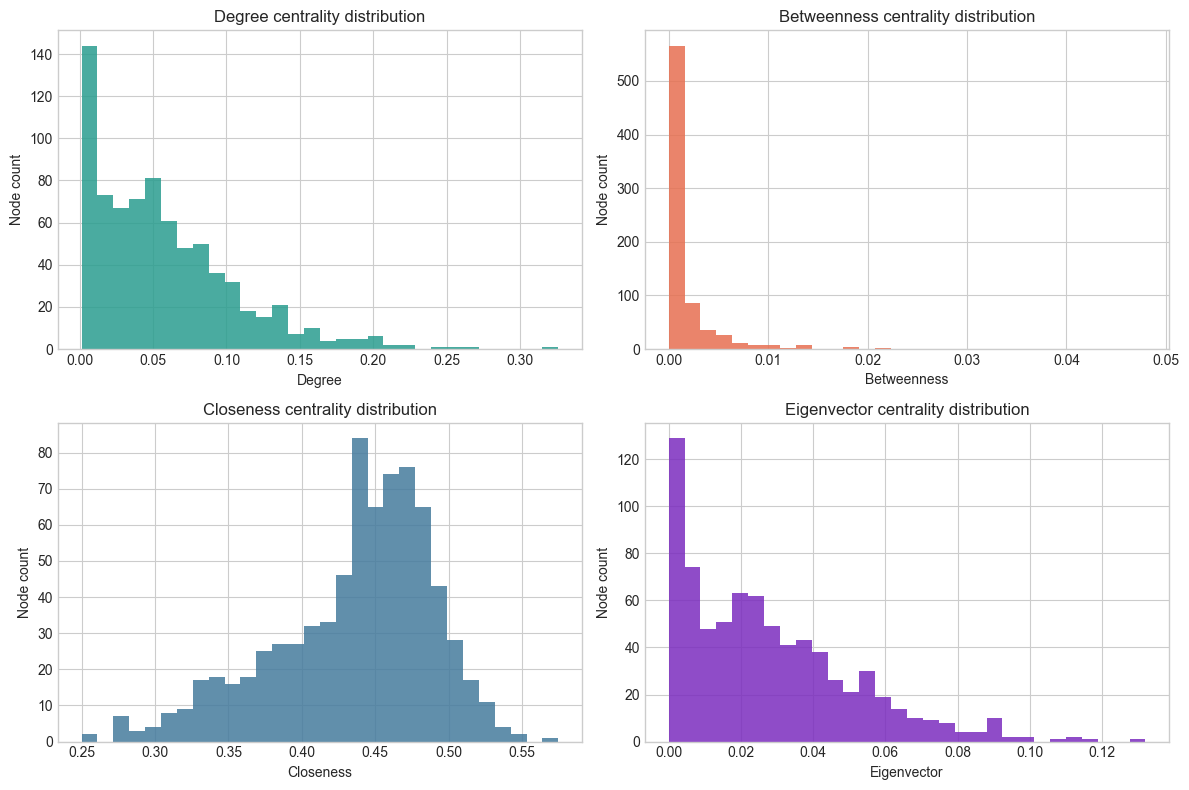

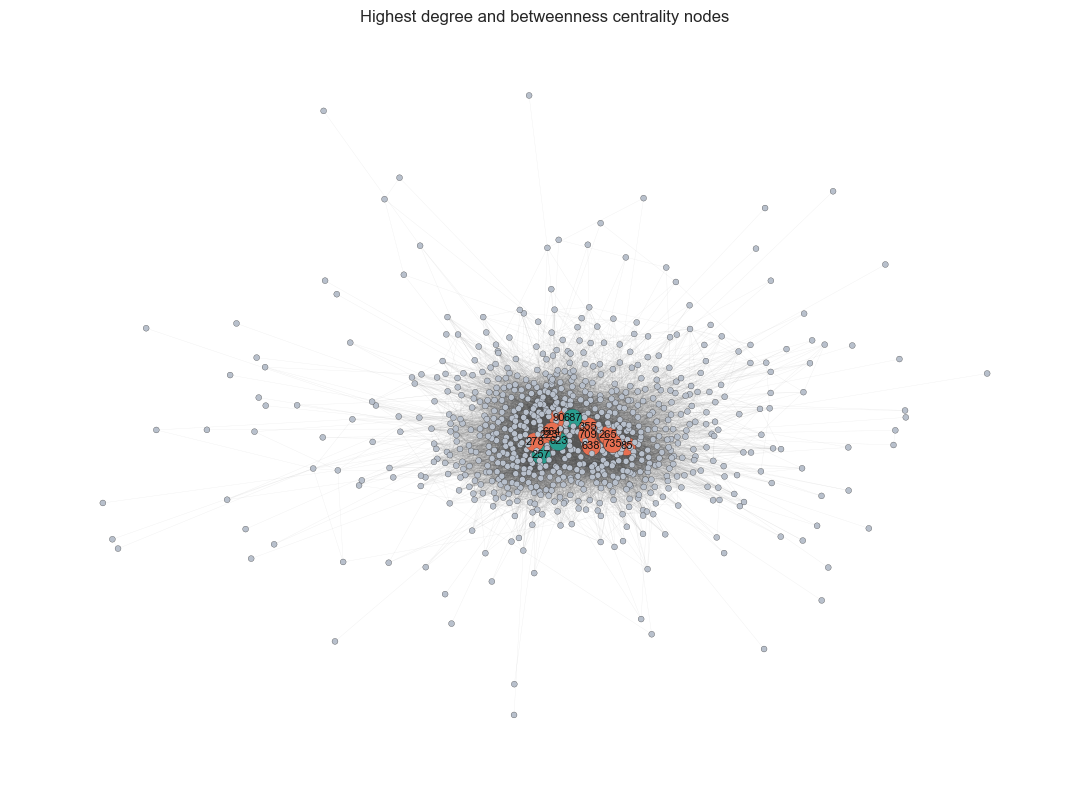

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
metrics = ["degree", "betweenness", "closeness", "eigenvector"]
colors = ["#2a9d8f", "#e76f51", "#457b9d", "#7b2cbf"]

for ax, metric, color in zip(axes.flatten(), metrics, colors):
    ax.hist(centrality_df[metric], bins=30, color=color, alpha=0.85)
    ax.set_title(f"{metric.title()} centrality distribution")
    ax.set_xlabel(metric.title())
    ax.set_ylabel("Node count")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_centrality_distributions.png", dpi=180)
plt.show()

top_betweenness_nodes = centrality_df.sort_values("betweenness", ascending=False).head(10)["node"].tolist()
highlight_nodes = set(top_degree_nodes) | set(top_betweenness_nodes)
node_colors = [
    "#e76f51" if node in top_betweenness_nodes else "#2a9d8f" if node in top_degree_nodes else "#b8c0cc"
    for node in G_lcc.nodes()
]
node_sizes = [180 if node in highlight_nodes else 18 for node in G_lcc.nodes()]

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G_lcc, pos_lcc, ax=ax, width=0.25, alpha=0.10, edge_color="#555555")
nx.draw_networkx_nodes(G_lcc, pos_lcc, ax=ax, node_color=node_colors, node_size=node_sizes, linewidths=0.2, edgecolors="#222222")
nx.draw_networkx_labels(
    G_lcc.subgraph(highlight_nodes),
    pos_lcc,
    ax=ax,
    font_size=8,
    font_color="#111111",
)
ax.set_title("Highest degree and betweenness centrality nodes")
ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_high_centrality_nodes.png", dpi=180)
plt.show()


**Interpretation.** The top-ranked nodes are likely socially central students because they combine high degree with high closeness and eigenvector scores. Nodes with high betweenness are especially important because they can connect otherwise separated friendship circles.


## 4. Shortest Path and Distance Structure


,Metric,Value
0,Average shortest path length,2.337848
1,Median pairwise shortest path length,2.000000
2,Maximum shortest path length / diameter,6.000000
3,Average distance from node 709,1.737533


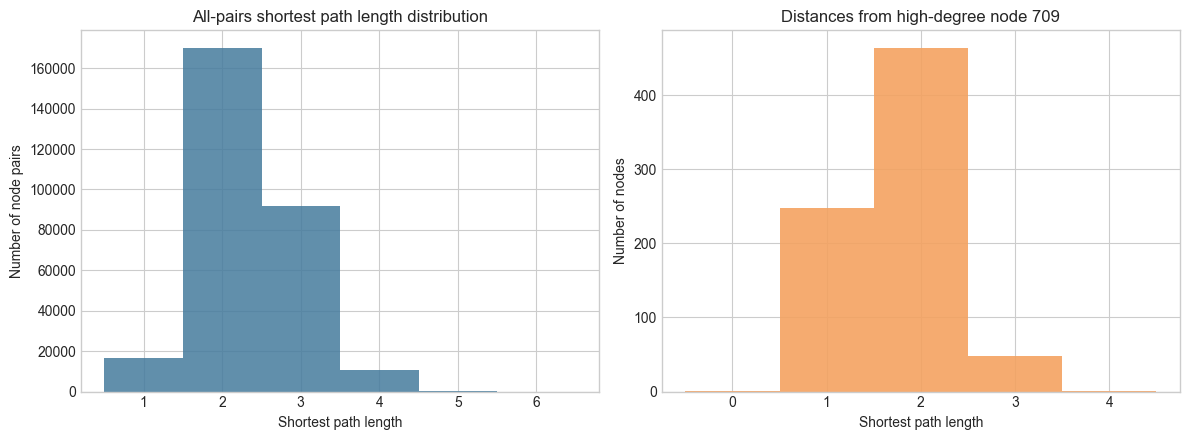

In [8]:
all_lengths = dict(nx.all_pairs_shortest_path_length(G_lcc))
pair_distances = [
    distance
    for source, target_lengths in all_lengths.items()
    for target, distance in target_lengths.items()
    if source < target
]

representative_node = int(centrality_df.sort_values("degree", ascending=False).iloc[0]["node"])
distances_from_representative = list(all_lengths[representative_node].values())

shortest_path_summary = pd.DataFrame(
    [
        ["Average shortest path length", nx.average_shortest_path_length(G_lcc)],
        ["Median pairwise shortest path length", statistics.median(pair_distances)],
        ["Maximum shortest path length / diameter", max(pair_distances)],
        [f"Average distance from node {representative_node}", np.mean(distances_from_representative)],
    ],
    columns=["Metric", "Value"],
)
display(shortest_path_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(pair_distances, bins=np.arange(0.5, max(pair_distances) + 1.5, 1), color="#457b9d", alpha=0.85)
axes[0].set_title("All-pairs shortest path length distribution")
axes[0].set_xlabel("Shortest path length")
axes[0].set_ylabel("Number of node pairs")

axes[1].hist(
    distances_from_representative,
    bins=np.arange(-0.5, max(distances_from_representative) + 1.5, 1),
    color="#f4a261",
    alpha=0.90,
)
axes[1].set_title(f"Distances from high-degree node {representative_node}")
axes[1].set_xlabel("Shortest path length")
axes[1].set_ylabel("Number of nodes")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_shortest_path_distributions.png", dpi=180)
plt.show()


**Interpretation.** Most node pairs are separated by only a few friendship steps, which is consistent with a compact university social network. The high-degree representative node is, on average, closer to the rest of the largest component than a random peripheral node would be.


## 5. Density, Degree Distribution, Clustering, Triangles, and Bridges


,Metric,Value
0,Graph density,0.056404
1,Number of connected components,4
2,Component sizes,"[762, 3, 2, 2]"
3,Mean degree,43.318596
4,Median degree,36
5,Maximum degree,248


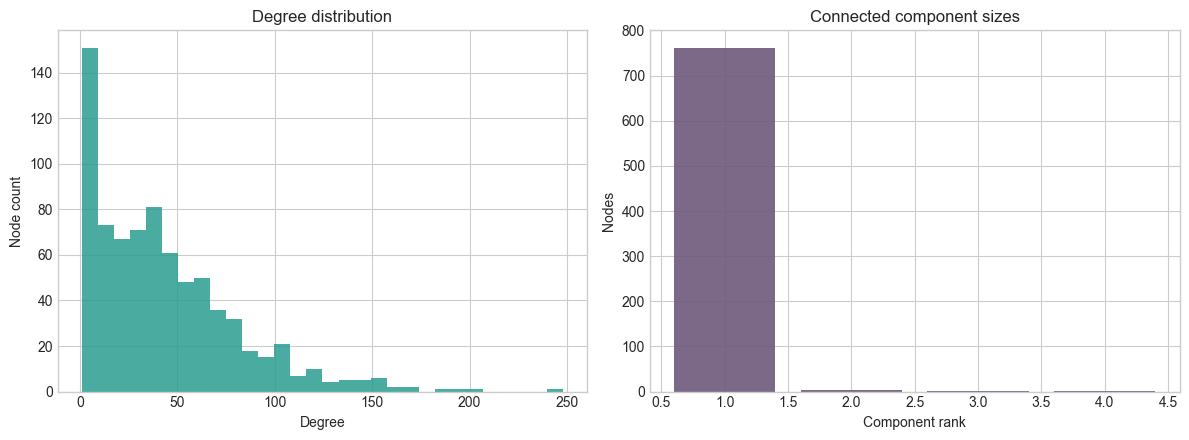

In [9]:
component_sizes = sorted([len(component) for component in nx.connected_components(G)], reverse=True)
degree_values = list(degrees.values())

component_degree_summary = pd.DataFrame(
    [
        ["Graph density", nx.density(G)],
        ["Number of connected components", nx.number_connected_components(G)],
        ["Component sizes", component_sizes],
        ["Mean degree", np.mean(degree_values)],
        ["Median degree", statistics.median(degree_values)],
        ["Maximum degree", max(degree_values)],
    ],
    columns=["Metric", "Value"],
)
display(component_degree_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(degree_values, bins=30, color="#2a9d8f", alpha=0.85)
axes[0].set_title("Degree distribution")
axes[0].set_xlabel("Degree")
axes[0].set_ylabel("Node count")

axes[1].bar(range(1, len(component_sizes) + 1), component_sizes, color="#6d597a", alpha=0.90)
axes[1].set_title("Connected component sizes")
axes[1].set_xlabel("Component rank")
axes[1].set_ylabel("Nodes")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "05_degree_and_components.png", dpi=180)
plt.show()


,Metric,Value
0,Average clustering coefficient,0.409294
1,Mean triangles per node,466.435631
2,Median triangles per node,259.000000
3,Maximum triangles for one node,3953.000000
4,Number of bridges,33.000000
5,Number of local bridges,100.000000


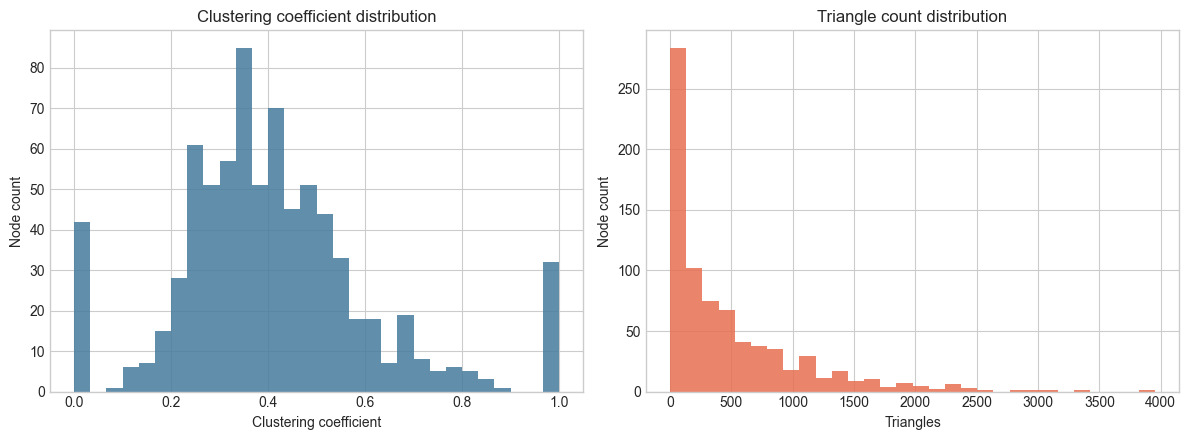

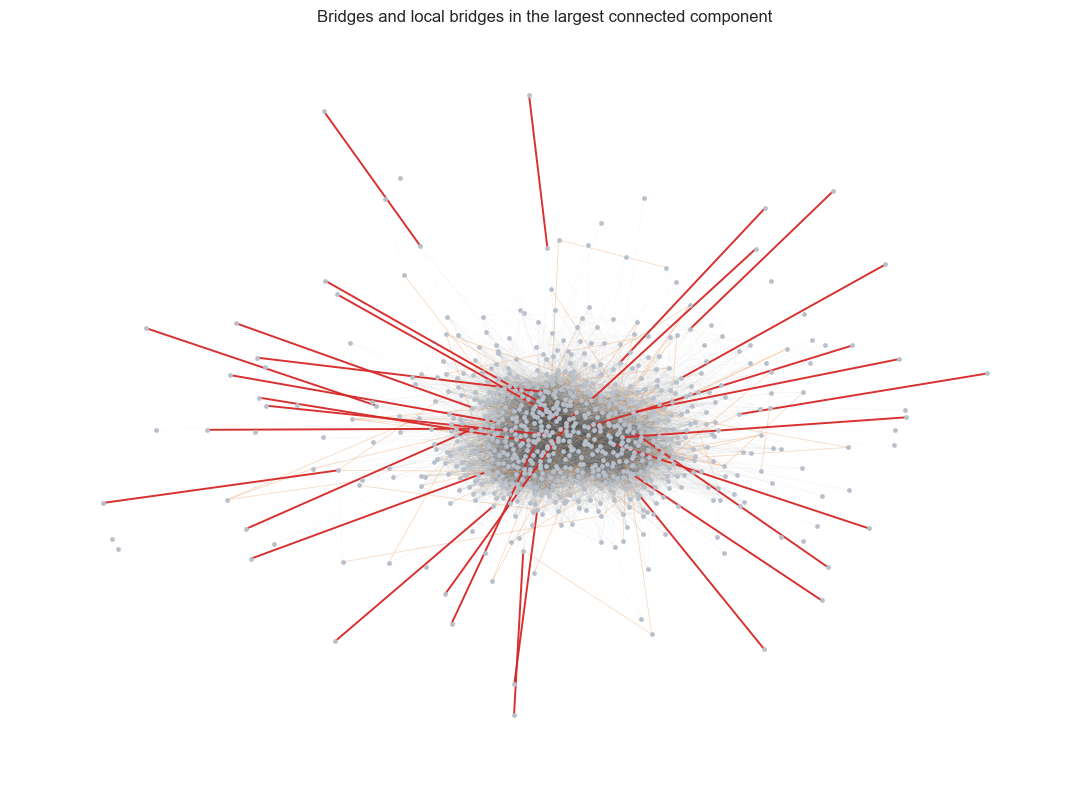

In [10]:
clustering_coefficients = nx.clustering(G)
triangle_counts = nx.triangles(G)
bridge_edges = list(nx.bridges(G))
local_bridge_edges = list(nx.local_bridges(G, with_span=False))

clustering_summary = pd.DataFrame(
    [
        ["Average clustering coefficient", nx.average_clustering(G)],
        ["Mean triangles per node", statistics.mean(triangle_counts.values())],
        ["Median triangles per node", statistics.median(triangle_counts.values())],
        ["Maximum triangles for one node", max(triangle_counts.values())],
        ["Number of bridges", len(bridge_edges)],
        ["Number of local bridges", len(local_bridge_edges)],
    ],
    columns=["Metric", "Value"],
)
display(clustering_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(list(clustering_coefficients.values()), bins=30, color="#457b9d", alpha=0.85)
axes[0].set_title("Clustering coefficient distribution")
axes[0].set_xlabel("Clustering coefficient")
axes[0].set_ylabel("Node count")

axes[1].hist(list(triangle_counts.values()), bins=30, color="#e76f51", alpha=0.85)
axes[1].set_title("Triangle count distribution")
axes[1].set_xlabel("Triangles")
axes[1].set_ylabel("Node count")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_clustering_and_triangles.png", dpi=180)
plt.show()

lcc_bridge_edges = [edge for edge in bridge_edges if edge[0] in G_lcc and edge[1] in G_lcc]
lcc_local_bridge_edges = [edge for edge in local_bridge_edges if edge[0] in G_lcc and edge[1] in G_lcc]

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G_lcc, pos_lcc, ax=ax, width=0.20, alpha=0.08, edge_color="#555555")
nx.draw_networkx_edges(G_lcc, pos_lcc, edgelist=lcc_local_bridge_edges, ax=ax, width=0.60, alpha=0.35, edge_color="#f4a261")
nx.draw_networkx_edges(G_lcc, pos_lcc, edgelist=lcc_bridge_edges, ax=ax, width=1.40, alpha=0.95, edge_color="#d62828")
nx.draw_networkx_nodes(G_lcc, pos_lcc, ax=ax, node_size=12, node_color="#b8c0cc", linewidths=0)
ax.set_title("Bridges and local bridges in the largest connected component")
ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_bridges_and_local_bridges.png", dpi=180)
plt.show()


**Interpretation.** The high clustering and large number of triangles show that many friendships occur inside tightly connected groups. Bridges and local bridges highlight weaker links between neighborhoods of the graph; these edges are important for connectivity even if they are not always the densest parts of the network.


## 6. Louvain Method Implementation

Louvain optimizes modularity, so it is usually fast on graphs of this size and tends to find communities with dense internal connections.


In [11]:
louvain_start = time.perf_counter()
louvain_partition = community_louvain.best_partition(G, random_state=RANDOM_SEED)
louvain_runtime = time.perf_counter() - louvain_start

louvain_communities_by_id = {}
for node, community_id in louvain_partition.items():
    louvain_communities_by_id.setdefault(community_id, set()).add(node)

louvain_communities = list(louvain_communities_by_id.values())
louvain_sizes = sorted([len(nodes) for nodes in louvain_communities], reverse=True)
louvain_modularity = modularity(G, louvain_communities)

louvain_summary = pd.DataFrame(
    [
        ["Number of communities", len(louvain_communities)],
        ["Modularity score", louvain_modularity],
        ["Runtime seconds", louvain_runtime],
        ["Community sizes descending", louvain_sizes],
    ],
    columns=["Metric", "Value"],
)
display(louvain_summary)

louvain_size_table = pd.DataFrame(
    sorted(
        [{"community": cid, "size": len(nodes)} for cid, nodes in louvain_communities_by_id.items()],
        key=lambda row: row["size"],
        reverse=True,
    )
)
display(louvain_size_table)


,Metric,Value
0,Number of communities,11
1,Modularity score,0.400862
2,Runtime seconds,0.083333
3,Community sizes descending,"[127, 117, 116, 110, 101, 95, 79, 17, 3, 2, 2]"


,community,size
0,2,127
1,8,117
2,0,116
3,4,110
4,1,101
5,6,95
6,3,79
7,7,17
8,5,3
9,9,2


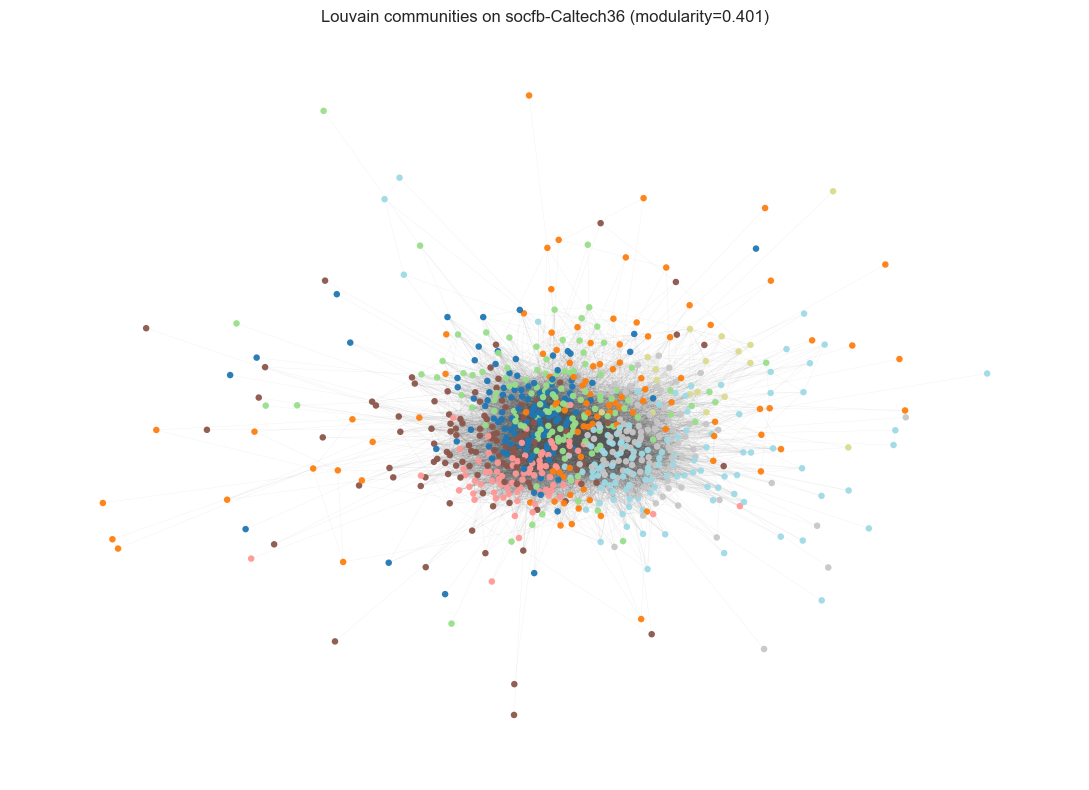

In [12]:
louvain_node_colors = [louvain_partition[node] for node in G_lcc.nodes()]

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G_lcc, pos_lcc, ax=ax, width=0.25, alpha=0.10, edge_color="#555555")
nx.draw_networkx_nodes(
    G_lcc,
    pos_lcc,
    ax=ax,
    node_color=louvain_node_colors,
    node_size=22,
    cmap="tab20",
    linewidths=0,
    alpha=0.95,
)
ax.set_title(f"Louvain communities on {DATASET_NAME} (modularity={louvain_modularity:.3f})")
ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_louvain_communities.png", dpi=180)
plt.show()


## 7. Girvan-Newman Method Implementation

Girvan-Newman repeatedly removes edges with high edge betweenness. The full exact algorithm can be slow on dense graphs, so this notebook uses NetworkX's Girvan-Newman implementation with a fixed-seed approximate edge-betweenness scorer. The method is applied to the largest connected component so that `k = 2, 3, 4` partitions are meaningful.


In [13]:
def approximate_most_valuable_edge(graph: nx.Graph):
    sample_size = min(80, max(10, int(graph.number_of_nodes() ** 0.5 * 4)))
    edge_scores = nx.edge_betweenness_centrality(graph, k=sample_size, seed=RANDOM_SEED)
    return max(edge_scores, key=edge_scores.get)


target_k_values = {2, 3, 4}
girvan_newman_partitions = {}
girvan_newman_rows = []

gn_start = time.perf_counter()
for communities_tuple in girvan_newman(G_lcc, most_valuable_edge=approximate_most_valuable_edge):
    communities = [set(community) for community in communities_tuple]
    community_count = len(communities)

    if community_count in target_k_values:
        partition_runtime = time.perf_counter() - gn_start
        community_sizes = sorted([len(community) for community in communities], reverse=True)
        partition_modularity = modularity(G_lcc, communities)
        girvan_newman_partitions[community_count] = communities
        girvan_newman_rows.append(
            {
                "k": community_count,
                "modularity": partition_modularity,
                "runtime_seconds": partition_runtime,
                "community_sizes": community_sizes,
            }
        )

    if community_count >= max(target_k_values):
        break

girvan_newman_summary = pd.DataFrame(girvan_newman_rows)
display(girvan_newman_summary)


,k,modularity,runtime_seconds,community_sizes
0,2,-1.803389e-09,0.285101,"[761, 1]"
1,3,-5.410166e-09,0.530831,"[760, 1, 1]"
2,4,-1.082033e-08,0.766230,"[759, 1, 1, 1]"


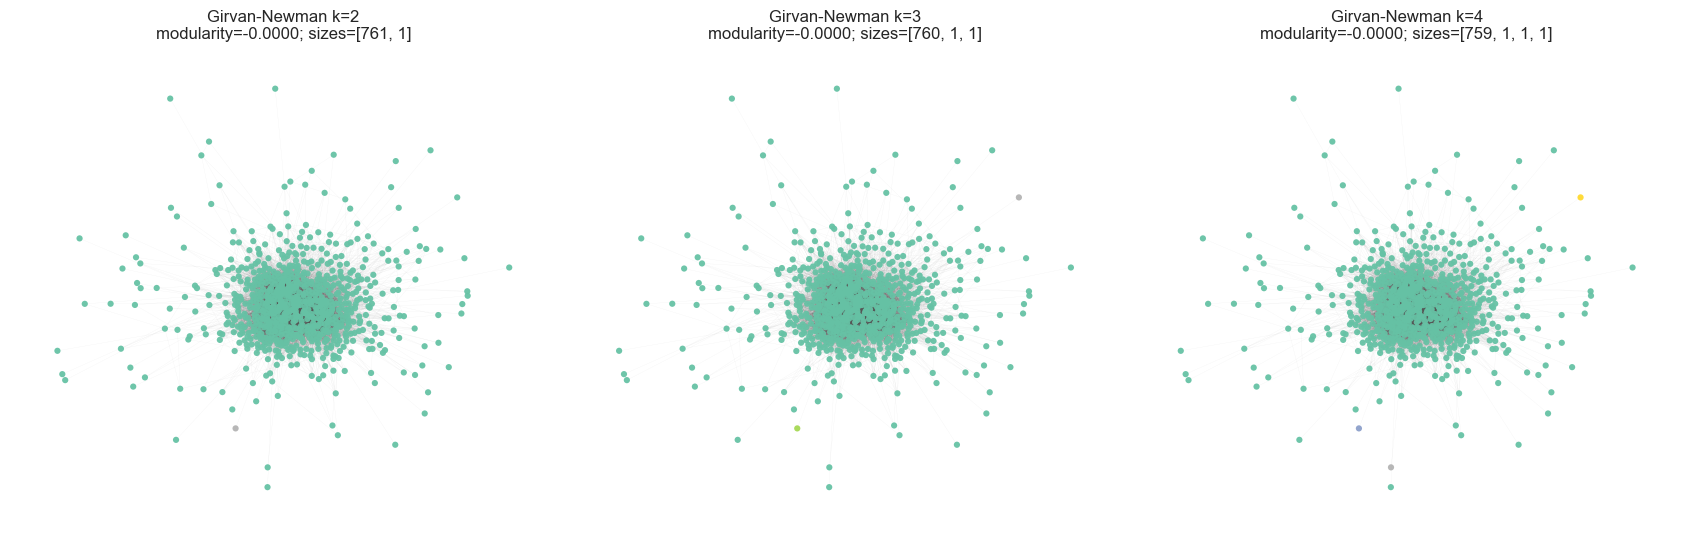

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

for ax, k in zip(axes, [2, 3, 4]):
    communities = girvan_newman_partitions[k]
    node_to_community = {
        node: index
        for index, community in enumerate(communities)
        for node in community
    }
    node_colors = [node_to_community[node] for node in G_lcc.nodes()]
    community_sizes = sorted([len(community) for community in communities], reverse=True)
    modularity_value = float(girvan_newman_summary.loc[girvan_newman_summary["k"] == k, "modularity"].iloc[0])

    nx.draw_networkx_edges(G_lcc, pos_lcc, ax=ax, width=0.20, alpha=0.08, edge_color="#555555")
    nx.draw_networkx_nodes(
        G_lcc,
        pos_lcc,
        ax=ax,
        node_color=node_colors,
        node_size=20,
        cmap="Set2",
        linewidths=0,
        alpha=0.95,
    )
    ax.set_title(f"Girvan-Newman k={k}\nmodularity={modularity_value:.4f}; sizes={community_sizes[:4]}")
    ax.axis("off")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "09_girvan_newman_communities.png", dpi=180)
plt.show()


## 8. Comparative Analysis


,method,graph_used,communities,modularity,runtime_seconds,largest_community_size,smallest_community_size,size_pattern
0,Louvain,Full graph,11,4.008625e-01,0.083333,127,2,"[127, 117, 116, 110, 101, 95, 79, 17, 3, 2, 2]"
1,Girvan-Newman k=2,Largest connected component,2,-1.803389e-09,0.285101,761,1,"[761, 1]"
2,Girvan-Newman k=3,Largest connected component,3,-5.410166e-09,0.530831,760,1,"[760, 1, 1]"
3,Girvan-Newman k=4,Largest connected component,4,-1.082033e-08,0.766230,759,1,"[759, 1, 1, 1]"


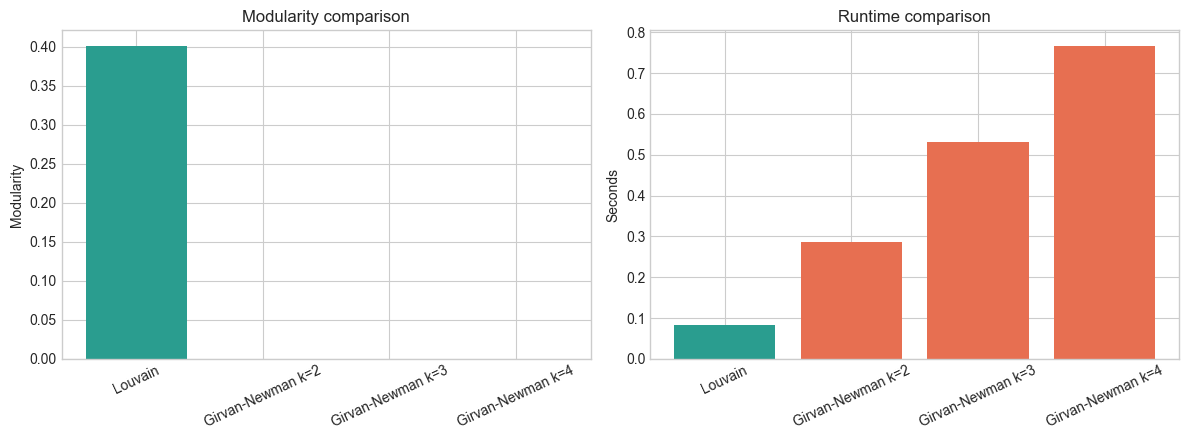

In [15]:
comparison_rows = [
    {
        "method": "Louvain",
        "graph_used": "Full graph",
        "communities": len(louvain_communities),
        "modularity": louvain_modularity,
        "runtime_seconds": louvain_runtime,
        "largest_community_size": max(louvain_sizes),
        "smallest_community_size": min(louvain_sizes),
        "size_pattern": str(louvain_sizes),
    }
]

for _, row in girvan_newman_summary.iterrows():
    sizes = row["community_sizes"]
    comparison_rows.append(
        {
            "method": f"Girvan-Newman k={int(row['k'])}",
            "graph_used": "Largest connected component",
            "communities": int(row["k"]),
            "modularity": float(row["modularity"]),
            "runtime_seconds": float(row["runtime_seconds"]),
            "largest_community_size": max(sizes),
            "smallest_community_size": min(sizes),
            "size_pattern": str(sizes),
        }
    )

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(comparison_df["method"], comparison_df["modularity"], color=["#2a9d8f", "#f4a261", "#f4a261", "#f4a261"])
axes[0].set_title("Modularity comparison")
axes[0].set_ylabel("Modularity")
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(comparison_df["method"], comparison_df["runtime_seconds"], color=["#2a9d8f", "#e76f51", "#e76f51", "#e76f51"])
axes[1].set_title("Runtime comparison")
axes[1].set_ylabel("Seconds")
axes[1].tick_params(axis="x", rotation=25)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "10_method_comparison.png", dpi=180)
plt.show()


**Comparison.** Louvain fits this dataset better than the Girvan-Newman partitions tested here. Louvain finds multiple medium-to-large communities and reaches a substantially higher modularity score, meaning it captures dense internal friendship groups more effectively. Girvan-Newman is useful for explaining bridge-like edges, but on this dense Caltech Facebook graph the first `k = 2, 3, 4` splits isolate peripheral nodes instead of producing balanced social communities. Its visual separation is therefore weaker for this dataset.

**Computation time.** Louvain is very fast because it directly optimizes modularity. The approximate Girvan-Newman run is also made runnable here, but the exact algorithm would be much more expensive because it recomputes edge-betweenness repeatedly.

**Interpretation in context.** In a university Facebook friendship network, detected communities likely represent social circles such as residence groups, year cohorts, classes, clubs, or friend groups. Louvain's larger communities are more plausible for this context because friendship ties usually cluster around shared environments rather than splitting first into individual peripheral users.

**Conclusion.** For `socfb-Caltech36`, Louvain is the better method for community detection because it gives higher modularity, clearer community structure, and more interpretable group sizes while running efficiently.
